# ひまわり8号 (Himawari-8) 事前学習 × METEOR-M2 欠損走査線インペインティング

自局で取得できた METEOR-M2 の完全無欠損画像は枚数に限りがあります。そこで本ノートブックでは、同じ東アジア・日本列島周辺（北緯 24°〜50°、東経 123°〜150°）を撮影した公開データセット **ひまわり8号 ([`PubAccount/Himawari-Japen`](https://huggingface.co/datasets/PubAccount/Himawari-Japen))** を活用します。

1. **ドメイン一致偽色合成**: ひまわり8号の `albedo_04` (近赤外)・`albedo_03` (赤)・`albedo_02` (緑) から、METEOR-M2 の `AVHRR_221_False_Color` 相当の合成画像を生成します。
2. **2段階学習（Pretraining → Fine-tuning）**: ひまわり8号の 4 季節データで事前学習したのち、METEOR-M2 データでファインチューニングします。
3. **定量比較 & 実欠損修復**: 「事前学習なし」と「ひまわり事前学習あり」を未知の実測パス（`20261026_003009`）で比較し、さらに実際の黒帯欠損を含む走査線の修復を試します。

## 1. 理論と目的の確認

| 項目 | ひまわり8号（`PubAccount/Himawari-Japen`） | METEOR-M2 MSU-MR（`AVHRR_221`） |
| :--- | :--- | :--- |
| 観測領域 | 北緯 24°〜50°, 東経 123°〜150°（日本周辺） | 北東アジア〜北海道・樺太・日本海 |
| R / G / B バンド | `albedo_04` (0.86μm) / `albedo_03` (0.64μm) / `albedo_02` (0.51μm) | NIR (Ch2) / Visible Red (Ch2) / Visible (Ch1) |
| 解像度・枚数 | `2601 × 2701` px / シーン（無欠損） | 幅 `1568` px（実測パスは限定的） |

同じ日本周辺の雲パターン（冬型の筋状雲・低気圧の渦・海と陸の境界）を数千パッチ規模で事前学習させることで、少数の METEOR 画像だけで学習する場合より高い汎化性能が期待できます。

## 2. データ準備（ひまわり8号 4季節シーン取得 ＋ パッチ抽出）

冬（1月）・春（4月）・夏（7月）・秋（10月）の昼（03:00 UTC = 12:00 JST）の NetCDF ファイルを 4 つ取得し、ローカルに偽色 PNG（あるいはパッチ配列）としてキャッシュします。

ひまわり8号 取得シーン数: 4, 各解像度: (1301, 1351, 3)


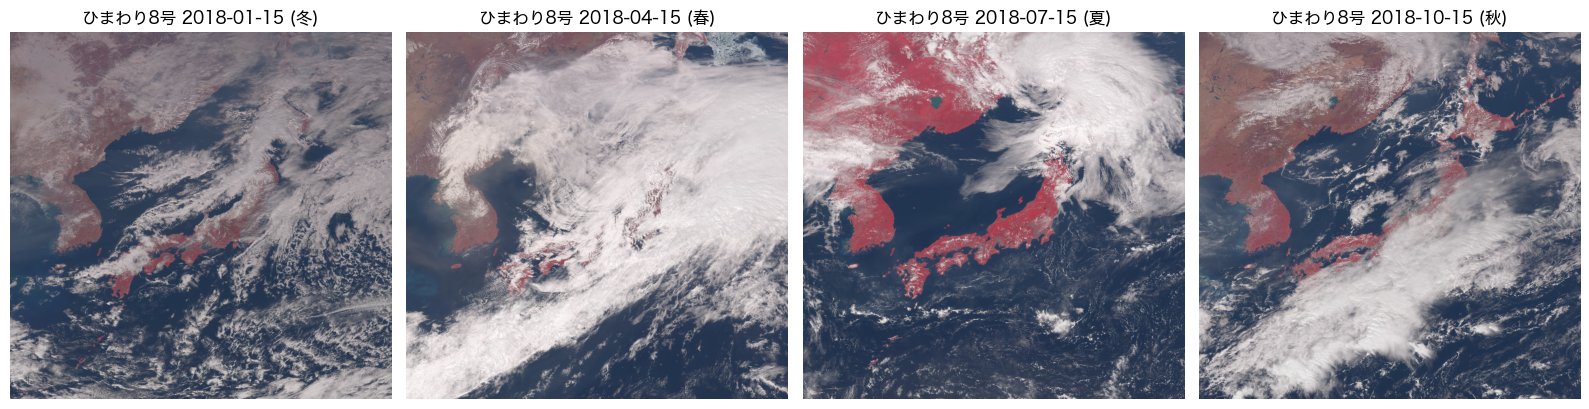

In [1]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

from pathlib import Path
import h5py
import numpy as np
from PIL import Image
from huggingface_hub import hf_hub_download

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "pyproject.toml").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent

METEOR_DIR = REPO_ROOT / "projects" / "radio-ml" / "data" / "meteor"
HIMAWARI_CACHE = REPO_ROOT / "projects" / "radio-ml" / "data" / "himawari_cache.npz"

HIMAWARI_FILES = [
    ("2018-01-15 (冬)", "201801/15/03/NC_H08_20180115_0300_r14_FLDK.02701_02601.nc"),
    ("2018-04-15 (春)", "201804/15/03/NC_H08_20180415_0300_r14_FLDK.02701_02601.nc"),
    ("2018-07-15 (夏)", "201807/15/03/NC_H08_20180715_0300_r14_FLDK.02701_02601.nc"),
    ("2018-10-15 (秋)", "201810/15/03/NC_H08_20181015_0300_r14_FLDK.02701_02601.nc"),
]

def load_himawari_false_color(nc_relpath: str, downsample: int = 2) -> np.ndarray:
    local_nc = hf_hub_download("PubAccount/Himawari-Japen", nc_relpath, repo_type="dataset")
    bands = []
    with h5py.File(local_nc, "r") as f:
        for key in ["albedo_04", "albedo_03", "albedo_02"]:
            ds = f[key]
            scale = float(np.atleast_1d(ds.attrs.get("scale_factor", 1.0))[0])
            offset = float(np.atleast_1d(ds.attrs.get("add_offset", 0.0))[0])
            arr = ds[::downsample, ::downsample].astype(np.float32) * scale + offset
            bands.append(arr)
    rgb = np.stack(bands, axis=-1)
    # AVHRR 221 風の自然な視認性になるようクリップ＋ガンマ補正
    rgb = np.power(np.clip(rgb, 0.0, 1.0), 1.0 / 2.2).astype(np.float32)
    return rgb

if HIMAWARI_CACHE.exists():
    cached = np.load(HIMAWARI_CACHE)
    himawari_scenes = [cached[f"scene_{i}"] for i in range(len(HIMAWARI_FILES))]
else:
    HIMAWARI_CACHE.parent.mkdir(parents=True, exist_ok=True)
    himawari_scenes = [load_himawari_false_color(rel) for _, rel in HIMAWARI_FILES]
    np.savez_compressed(HIMAWARI_CACHE, **{f"scene_{i}": s for i, s in enumerate(himawari_scenes)})

print(f"ひまわり8号 取得シーン数: {len(himawari_scenes)}, 各解像度: {himawari_scenes[0].shape}")

# サンプル表示
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (label, _), img in zip(axes, HIMAWARI_FILES, himawari_scenes):
    ax.imshow(img)
    ax.set_title(f"ひまわり8号 {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### パッチ抽出（ひまわり事前学習用 / METEOR ファインチューニング用 / 未知実測 Val 用）

In [2]:
def extract_patches_from_arrays(arrays, patch_size=64, stride=48, min_valid_ratio=1.0, min_std=0.02):
    patches = []
    for arr in arrays:
        h, w, _ = arr.shape
        for y in range(0, h - patch_size + 1, stride):
            for x in range(0, w - patch_size + 1, stride):
                crop = arr[y:y + patch_size, x:x + patch_size]
                if (crop.max(axis=2) > 0.02).mean() >= min_valid_ratio and crop.std() > min_std:
                    patches.append(crop.transpose(2, 0, 1))
    return np.stack(patches).astype(np.float32)

himawari_patches = extract_patches_from_arrays(himawari_scenes, patch_size=64, stride=48, min_valid_ratio=1.0)

golden_arr = np.asarray(
    Image.open(METEOR_DIR / "METEOR-M2_GOLDEN_1791698496" / "msu_mr_rgb_AVHRR_221_False_Color.png").convert("RGB"),
    dtype=np.float32,
) / 255.0
real_val_arr = np.asarray(
    Image.open(METEOR_DIR / "METEOR-M2 3_20261026_003009" / "msu_mr_rgb_AVHRR_221_False_Color.png").convert("RGB"),
    dtype=np.float32,
) / 255.0

meteor_ft_patches = extract_patches_from_arrays([golden_arr], patch_size=64, stride=48, min_valid_ratio=1.0)
meteor_val_patches = extract_patches_from_arrays([real_val_arr], patch_size=64, stride=32, min_valid_ratio=1.0)

print(f"ひまわり事前学習パッチ: {len(himawari_patches)} 枚")
print(f"METEOR ファインチューニング (Golden): {len(meteor_ft_patches)} 枚")
print(f"METEOR 未知実測 Val (10/26): {len(meteor_val_patches)} 枚")

ひまわり事前学習パッチ: 2787 枚
METEOR ファインチューニング (Golden): 684 枚
METEOR 未知実測 Val (10/26): 57 枚


## 3. 可視化と考察：2段階学習（ひまわり事前学習 → METEOR ファインチューニング）の比較

1. **Baseline（事前学習なし）**: METEOR 少データ（Golden, または極小サンプル想定の 100 枚サブセット / 全 684 枚）のみで学習
2. **Pretrained + Finetuned（ひまわり8号 事前学習あり）**: ひまわり8号で 15 エポック事前学習した重みから METEOR でファインチューニング

損失には L1 損失に加えて **エッジ勾配損失（Sobel 勾配 L1）** を加え、雲の輪郭や海岸線がぼやけにくくなるようにしています。

使用デバイス: mps


ひまわり事前学習のみ (Zero-shot on METEOR 10/26) Val Hole L1: 0.0909


最終 Val Hole L1 (未知実測 10/26) -> 事前学習なし: 0.0833 | ひまわり事前学習+FT: 0.0692


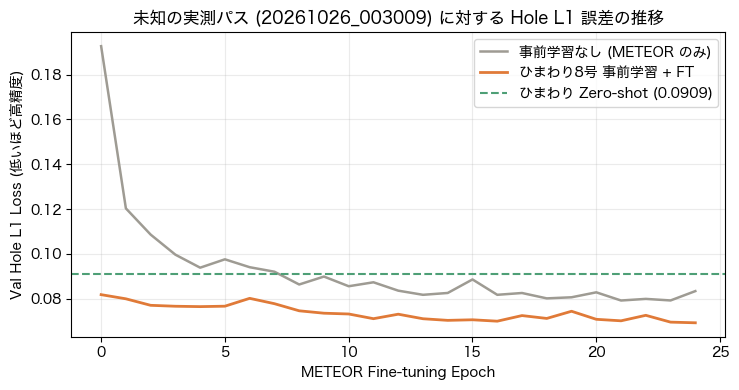

In [3]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("使用デバイス:", device)

class StripeMaskDataset(Dataset):
    def __init__(self, patches: np.ndarray, fixed_seed: int | None = None):
        self.patches = torch.from_numpy(patches)
        self.fixed_seed = fixed_seed

    def __len__(self):
        return len(self.patches)

    def __getitem__(self, idx):
        clean = self.patches[idx]
        _, h, w = clean.shape
        rng = np.random.default_rng(self.fixed_seed + idx) if self.fixed_seed is not None else np.random.default_rng()
        mask = torch.ones((1, h, w), dtype=torch.float32)
        n_stripes = int(rng.integers(1, 3))
        for _ in range(n_stripes):
            stripe_h = int(rng.integers(6, 15))
            y0 = int(rng.integers(4, h - stripe_h - 4))
            mask[:, y0:y0 + stripe_h, :] = 0.0
        return clean * mask, mask, clean

class MiniUNet(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(4, base, 3, padding=1), nn.ReLU(), nn.Conv2d(base, base, 3, padding=1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base * 2, 3, padding=1), nn.ReLU(), nn.Conv2d(base * 2, base * 2, 3, padding=1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        self.bottleneck = nn.Sequential(nn.Conv2d(base * 2, base * 4, 3, padding=1), nn.ReLU(), nn.Conv2d(base * 4, base * 4, 3, padding=1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = nn.Sequential(nn.Conv2d(base * 4, base * 2, 3, padding=1), nn.ReLU(), nn.Conv2d(base * 2, base * 2, 3, padding=1), nn.ReLU())
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = nn.Sequential(nn.Conv2d(base * 2, base, 3, padding=1), nn.ReLU(), nn.Conv2d(base, base, 3, padding=1), nn.ReLU())
        self.out_conv = nn.Conv2d(base, 3, 1)

    def forward(self, corrupted, mask):
        x = torch.cat([corrupted, mask], dim=1)
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bottleneck(self.pool2(e2))
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        pred = torch.sigmoid(self.out_conv(d1))
        return corrupted * mask + pred * (1.0 - mask)

def hole_and_edge_loss(pred, clean, mask):
    hole = 1.0 - mask
    l1 = (torch.abs(pred - clean) * hole).sum() / (hole.sum() * 3.0 + 1e-6)
    # 縦方向・横方向の差分（エッジ連続性）
    dy_p, dy_c = pred[:, :, 1:, :] - pred[:, :, :-1, :], clean[:, :, 1:, :] - clean[:, :, :-1, :]
    dx_p, dx_c = pred[:, :, :, 1:] - pred[:, :, :, :-1], clean[:, :, :, 1:] - clean[:, :, :, :-1]
    edge_loss = (torch.abs(dy_p - dy_c).mean() + torch.abs(dx_p - dx_c).mean()) * 0.5
    return l1 + 0.5 * edge_loss, l1

def evaluate_hole_l1(model, loader):
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for corr, msk, cln in loader:
            corr, msk, cln = corr.to(device), msk.to(device), cln.to(device)
            out = model(corr, msk)
            _, l1 = hole_and_edge_loss(out, cln, msk)
            total += l1.item() * len(corr)
            n += len(corr)
    return total / n

val_loader = DataLoader(StripeMaskDataset(meteor_val_patches, fixed_seed=100), batch_size=16, shuffle=False)
ft_loader = DataLoader(StripeMaskDataset(meteor_ft_patches), batch_size=16, shuffle=True)
pre_loader = DataLoader(StripeMaskDataset(himawari_patches), batch_size=32, shuffle=True)

# --- A. 事前学習なし (Scratch on METEOR only) ---
torch.manual_seed(42)
scratch_model = MiniUNet(base=32).to(device)
opt_s = torch.optim.Adam(scratch_model.parameters(), lr=1.5e-3)
scratch_val = []
for epoch in range(25):
    scratch_model.train()
    for corr, msk, cln in ft_loader:
        corr, msk, cln = corr.to(device), msk.to(device), cln.to(device)
        opt_s.zero_grad()
        loss, _ = hole_and_edge_loss(scratch_model(corr, msk), cln, msk)
        loss.backward()
        opt_s.step()
    scratch_val.append(evaluate_hole_l1(scratch_model, val_loader))

# --- B. ひまわり8号 事前学習 -> METEOR ファインチューニング ---
torch.manual_seed(42)
pre_model = MiniUNet(base=32).to(device)
opt_p = torch.optim.Adam(pre_model.parameters(), lr=1.5e-3)
for epoch in range(15):
    pre_model.train()
    for corr, msk, cln in pre_loader:
        corr, msk, cln = corr.to(device), msk.to(device), cln.to(device)
        opt_p.zero_grad()
        loss, _ = hole_and_edge_loss(pre_model(corr, msk), cln, msk)
        loss.backward()
        opt_p.step()

zero_shot_val = evaluate_hole_l1(pre_model, val_loader)
print(f"ひまわり事前学習のみ (Zero-shot on METEOR 10/26) Val Hole L1: {zero_shot_val:.4f}")

opt_ft = torch.optim.Adam(pre_model.parameters(), lr=5e-4)
pre_ft_val = []
for epoch in range(25):
    pre_model.train()
    for corr, msk, cln in ft_loader:
        corr, msk, cln = corr.to(device), msk.to(device), cln.to(device)
        opt_ft.zero_grad()
        loss, _ = hole_and_edge_loss(pre_model(corr, msk), cln, msk)
        loss.backward()
        opt_ft.step()
    pre_ft_val.append(evaluate_hole_l1(pre_model, val_loader))

print(f"最終 Val Hole L1 (未知実測 10/26) -> 事前学習なし: {scratch_val[-1]:.4f} | ひまわり事前学習+FT: {pre_ft_val[-1]:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 4.0))
ax.plot(scratch_val, label="事前学習なし (METEOR のみ)", color="#9E9B93", lw=1.8)
ax.plot(pre_ft_val, label="ひまわり8号 事前学習 + FT", color="#E07A38", lw=2.0)
ax.axhline(zero_shot_val, linestyle="--", color="#4E9F76", label=f"ひまわり Zero-shot ({zero_shot_val:.4f})")
ax.set_title("未知の実測パス (20261026_003009) に対する Hole L1 誤差の推移")
ax.set_xlabel("METEOR Fine-tuning Epoch")
ax.set_ylabel("Val Hole L1 Loss (低いほど高精度)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 3.2 復元結果の比較（事前学習なし vs ひまわり事前学習+FT）＆ 実欠損の修復テスト
上段は未知実測パス（`10/26`）の疑似マスク比較、下段は実際の実測パス（`10/26` / `10/27`）に含まれる**本物の黒帯欠損（幅 8〜16 px）**に対してモデルを適用してみた結果です。

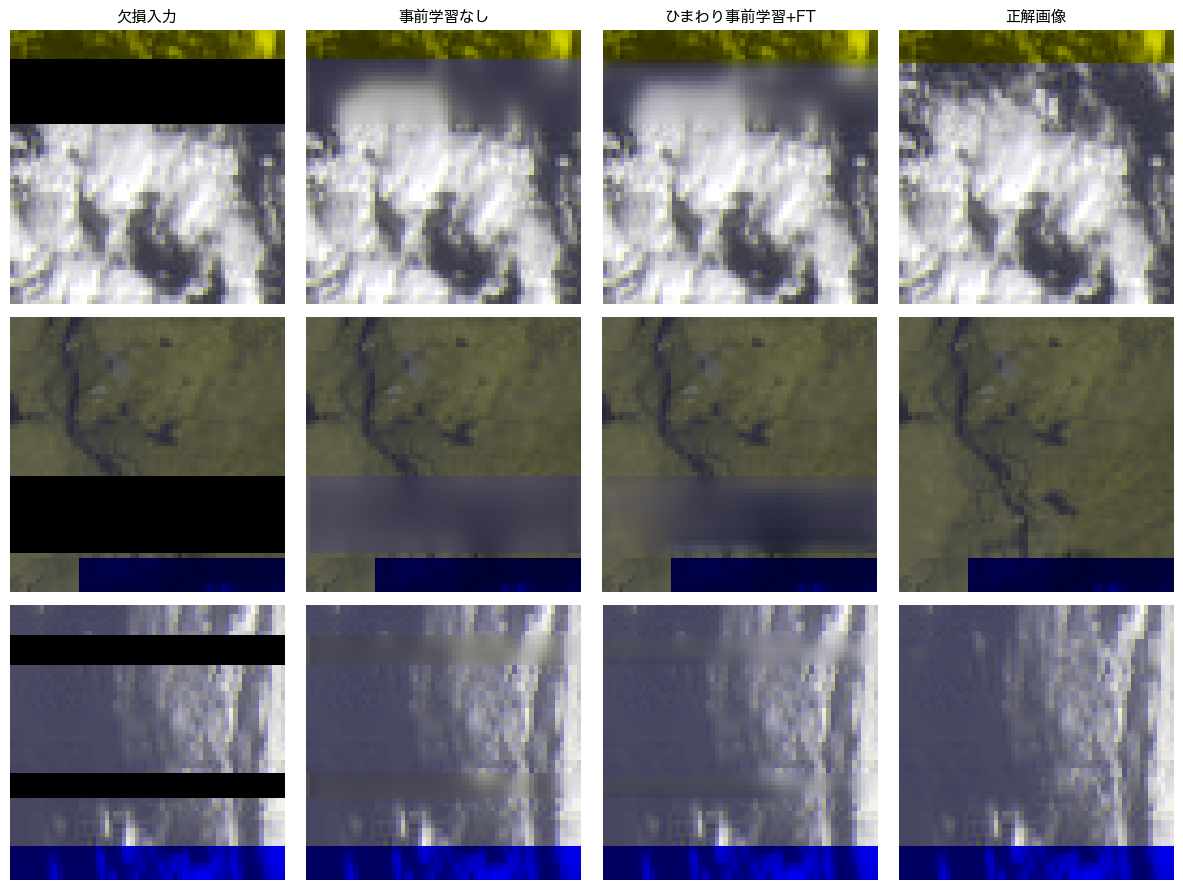

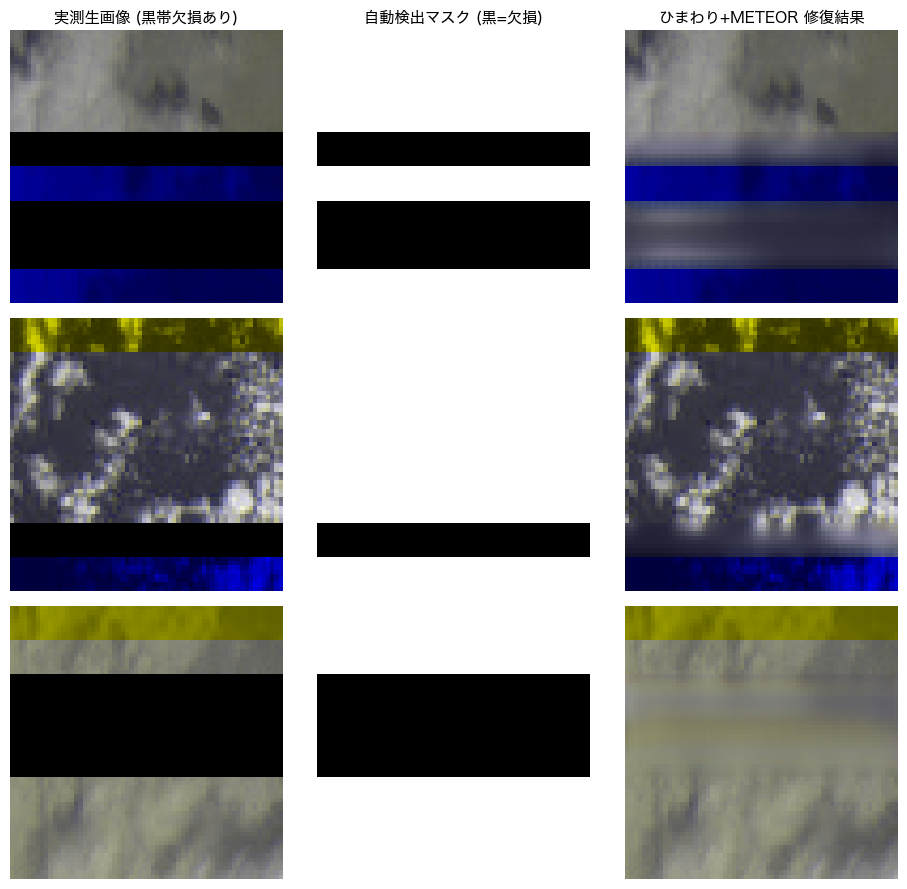

In [4]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

val_ds = StripeMaskDataset(meteor_val_patches, fixed_seed=100)
sample_indices = np.linspace(0, len(val_ds) - 1, min(3, len(val_ds)), dtype=int)

fig, axes = plt.subplots(len(sample_indices), 4, figsize=(12, 3.0 * len(sample_indices)))
scratch_model.eval()
pre_model.eval()
with torch.no_grad():
    for r_idx, s_idx in enumerate(sample_indices):
        corr, msk, cln = val_ds[int(s_idx)]
        b_corr = corr.unsqueeze(0).to(device)
        b_msk = msk.unsqueeze(0).to(device)
        pred_s = scratch_model(b_corr, b_msk).squeeze(0).cpu()
        pred_p = pre_model(b_corr, b_msk).squeeze(0).cpu()
        for c_idx, (t_img, title) in enumerate([
            (corr, "欠損入力"),
            (pred_s, "事前学習なし"),
            (pred_p, "ひまわり事前学習+FT"),
            (cln, "正解画像"),
        ]):
            ax = axes[r_idx, c_idx]
            ax.imshow(t_img.permute(1, 2, 0).numpy())
            if r_idx == 0:
                ax.set_title(title, fontsize=11)
            ax.axis("off")

plt.tight_layout()
plt.show()

# --- 本物の黒帯欠損を含む実測パッチへの適用デモ ---
real_hole_patches = []
used_y = []
h, w, _ = real_val_arr.shape
for y in range(0, h - 64 + 1, 8):
    if any(abs(y - uy) < 48 for uy in used_y):
        continue
    for x in range(150, w - 150 - 64 + 1, 64):
        crop = real_val_arr[y:y + 64, x:x + 64]
        valid_px = (crop.max(axis=2) > 0.03)
        row_valid = valid_px.mean(axis=1)
        # 上下は生きていて、途中に水平黒帯欠損があり、雲や陸の模様がある箇所を抽出
        if (
            0.60 <= valid_px.mean() <= 0.94
            and row_valid[:6].mean() > 0.6
            and row_valid[-6:].mean() > 0.6
            and row_valid.min() < 0.2
            and crop.std() > 0.06
        ):
            real_hole_patches.append((crop, valid_px.astype(np.float32)))
            used_y.append(y)
            break
    if len(real_hole_patches) >= 3:
        break

if real_hole_patches:
    fig, axes = plt.subplots(len(real_hole_patches), 3, figsize=(9.5, 3.0 * len(real_hole_patches)))
    if len(real_hole_patches) == 1:
        axes = np.array([axes])
    with torch.no_grad():
        for r_idx, (crop, vmask) in enumerate(real_hole_patches):
            t_img = torch.from_numpy(crop.transpose(2, 0, 1)).unsqueeze(0).to(device)
            t_msk = torch.from_numpy(vmask[None, None, ...]).to(device)
            repaired = pre_model(t_img, t_msk).squeeze(0).cpu().permute(1, 2, 0).numpy()
            for c_idx, (img_show, title) in enumerate([
                (crop, "実測生画像 (黒帯欠損あり)"),
                (vmask, "自動検出マスク (黒=欠損)"),
                (repaired, "ひまわり+METEOR 修復結果"),
            ]):
                ax = axes[r_idx, c_idx]
                ax.imshow(img_show, cmap="gray" if img_show.ndim == 2 else None)
                if r_idx == 0:
                    ax.set_title(title, fontsize=11)
                ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("条件に合う実欠損パッチが見つかりませんでした。")

## 4. 共通ベンチマーク評価：ベスト実測画像（`METEOR-M2 3_20261026_003009`, `1568×792`）全体への適用デモ

`02` と同じ共通指標（`Benchmark Hole L1`, `Hole PSNR [dB]`, `Vertical Seam Jump L1`）のもとで、「事前学習なし」vs「ひまわり8号事前学習 + FT」をベスト実測フル画像 `1568×792` 全体へ適用して比較します。

[03 比較] 事前学習なし     -> Hole L1: 0.0838 | Hole PSNR: 18.55 dB | Seam(Local): 0.0220
[03 比較] ひまわり事前学習+FT -> Hole L1: 0.0699 | Hole PSNR: 19.37 dB | Seam(Local): 0.0229
参考 (Before 元画像)       -> Seam: 0.0221 | 有効画素率: 44.8% -> Local: 75.4%


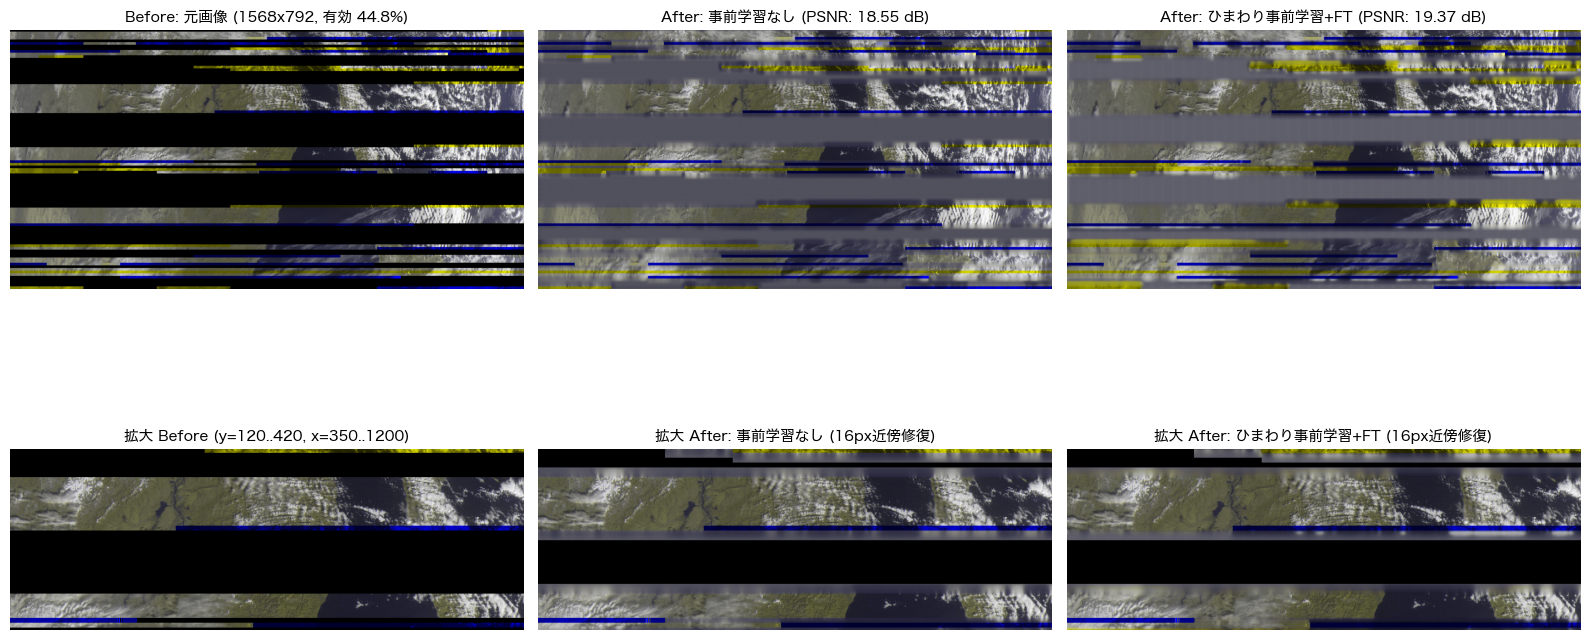

In [5]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

from scipy.ndimage import binary_dilation

def compute_common_hole_metrics(net, loader):
    net.eval()
    abs_sum, sq_sum, px_sum = 0.0, 0.0, 0.0
    with torch.no_grad():
        for corr, msk, cln in loader:
            corr, msk, cln = corr.to(device), msk.to(device), cln.to(device)
            out = net(corr, msk)
            hole = (1.0 - msk).expand_as(cln)
            diff = out - cln
            abs_sum += (torch.abs(diff) * hole).sum().item()
            sq_sum += ((diff ** 2) * hole).sum().item()
            px_sum += hole.sum().item()
    l1 = abs_sum / max(px_sum, 1e-6)
    mse = sq_sum / max(px_sum, 1e-6)
    psnr = -10.0 * np.log10(max(mse, 1e-12))
    return l1, psnr

def inpaint_full_image_tiled(net, img_hwc: np.ndarray, valid_hw1: np.ndarray, patch_size=64, stride=32, batch_size=128):
    h, w, c = img_hwc.shape
    ys = list(range(0, h - patch_size + 1, stride))
    if ys[-1] != h - patch_size:
        ys.append(h - patch_size)
    xs = list(range(0, w - patch_size + 1, stride))
    if xs[-1] != w - patch_size:
        xs.append(w - patch_size)

    win_1d = np.hanning(patch_size + 4)[2:-2].astype(np.float32)
    win_2d = np.maximum(np.outer(win_1d, win_1d), 0.05)
    coords = [(y, x) for y in ys for x in xs]

    acc = np.zeros((h, w, c), dtype=np.float32)
    wsum = np.zeros((h, w, 1), dtype=np.float32)
    net.eval()
    with torch.no_grad():
        for i in range(0, len(coords), batch_size):
            batch_coords = coords[i:i + batch_size]
            b_img = np.stack([img_hwc[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in batch_coords])
            b_msk = np.stack([valid_hw1[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in batch_coords])
            pred = net(torch.from_numpy(b_img).to(device), torch.from_numpy(b_msk).to(device)).cpu().numpy()
            for idx, (y, x) in enumerate(batch_coords):
                acc[y:y + patch_size, x:x + patch_size] += pred[idx].transpose(1, 2, 0) * win_2d[..., None]
                wsum[y:y + patch_size, x:x + patch_size] += win_2d[..., None]

    merged = np.clip(acc / np.maximum(wsum, 1e-6), 0.0, 1.0)
    return img_hwc * valid_hw1 + merged * (1.0 - valid_hw1)

l1_s, psnr_s = compute_common_hole_metrics(scratch_model, val_loader)
l1_p, psnr_p = compute_common_hole_metrics(pre_model, val_loader)

valid_2d = real_val_arr.max(axis=2) > 0.02
valid_hw1 = valid_2d[..., None].astype(np.float32)
near_mask = binary_dilation(valid_2d, structure=np.ones((33, 1), dtype=bool))[..., None].astype(np.float32)

full_scratch = inpaint_full_image_tiled(scratch_model, real_val_arr, valid_hw1)
full_pre = inpaint_full_image_tiled(pre_model, real_val_arr, valid_hw1)
local_scratch = real_val_arr * valid_hw1 + full_scratch * (1.0 - valid_hw1) * near_mask
local_pre = real_val_arr * valid_hw1 + full_pre * (1.0 - valid_hw1) * near_mask

def seam_jump(arr):
    return float(np.abs(arr[1:] - arr[:-1]).mean())

print(f"[03 比較] 事前学習なし     -> Hole L1: {l1_s:.4f} | Hole PSNR: {psnr_s:.2f} dB | Seam(Local): {seam_jump(local_scratch):.4f}")
print(f"[03 比較] ひまわり事前学習+FT -> Hole L1: {l1_p:.4f} | Hole PSNR: {psnr_p:.2f} dB | Seam(Local): {seam_jump(local_pre):.4f}")
print(f"参考 (Before 元画像)       -> Seam: {seam_jump(real_val_arr):.4f} | 有効画素率: {valid_2d.mean()*100:.1f}% -> Local: {(local_pre.max(axis=2)>0.02).mean()*100:.1f}%")

y0, y1, x0, x1 = 120, 420, 350, 1200
fig, axes = plt.subplots(2, 3, figsize=(16, 9.2))
top_items = [
    (real_val_arr, f"Before: 元画像 (1568x792, 有効 {valid_2d.mean()*100:.1f}%)"),
    (full_scratch, f"After: 事前学習なし (PSNR: {psnr_s:.2f} dB)"),
    (full_pre, f"After: ひまわり事前学習+FT (PSNR: {psnr_p:.2f} dB)"),
]
bot_items = [
    (real_val_arr[y0:y1, x0:x1], f"拡大 Before (y={y0}..{y1}, x={x0}..{x1})"),
    (local_scratch[y0:y1, x0:x1], "拡大 After: 事前学習なし (16px近傍修復)"),
    (local_pre[y0:y1, x0:x1], "拡大 After: ひまわり事前学習+FT (16px近傍修復)"),
]
for col, (im_t, t_title) in enumerate(top_items):
    axes[0, col].imshow(im_t)
    axes[0, col].set_title(t_title, fontsize=10.5)
    axes[0, col].axis("off")
for col, (im_b, b_title) in enumerate(bot_items):
    axes[1, col].imshow(im_b)
    axes[1, col].set_title(b_title, fontsize=10.5)
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()